# Delayed full feedback control and chaos control

### Problem
The paper states that in a nonlinear dynamical system
> ẋ=f(x)

- **x ∈ R<sup>n</sup>** is the *state vector* (so the system is n-dimensional).

- **f:R<sup>n</sup>→R<sup>n</sup>** is a *piecewise continuously differentiable* function (smooth except maybe at some boundaries).

- **x<sup>∗</sup>** is an equilibrium point of the system, and specifically an unstable hyperbolic equilibrium (near x<sup>*</sup>, solutions move away rather than stay close).

***Goal:** design a control input that makes x<sup>*</sup> stable, even though it is naturally unstable.*

### Adding Control with Delay
The system was modified by adding an input u(t):

> ẋ =f(x)+u(t)  ....<sub>(2)</sub>

Here u(t) is a time-delayed feedback control: it uses past values of x to decide what input to apply now.

The proposed control law is

> u(t)=K(t)(x(t−2τ)−x(t−τ))  ....<sub>(3)</sub>

- **τ>0τ>0** is a fixed time-delay.

- The control uses the difference between the state at two past times: **t−2τt−2τ** and **t−τt−τ**.
Intuition: if the system is unstable and tends to grow, this difference tells you how fast it is “escaping,” and you push it back.

So the closed-loop system is given by equations (2) and (3):
> ẋ=f(x)+K(t)(x(t−2τ)−x(t−τ))  ....<sub>(4)</sub>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def run_simulation(ode_func, x_star, K, tau, delta, initial_state, t_max):
    dt = 0.001
    steps = int(t_max / dt)
    history = np.zeros((steps, 3))
    times = np.linspace(0, t_max, steps)
    
    # Assign to the first index instead of overwriting the array
    history[0] = initial_state 
    control_activated = False
    
    for i in range(steps - 1):
        t = times[i]
        x_curr = history[i]
        
        # Check for control activation based on distance to equilibrium
        if not control_activated and np.linalg.norm(x_curr - x_star) < delta:
            control_activated = True

        u = np.zeros(3)
        if control_activated:
            idx_tau = i - int(tau / dt)
            idx_2tau = i - int(2 * tau / dt)
            
            if idx_2tau >= 0:
                # Periodic gain K(t) 
                period = 3 * tau
                if (2 * tau) <= (t % period) < (3 * tau):
                    gain_t = K
                else:
                    gain_t = np.zeros((3, 3))
                
                # D2FC Control Law: K(t) * [x(t-2tau) - x(t-tau)] 
                u = gain_t @ (history[idx_2tau] - history[idx_tau])

        history[i+1] = x_curr + (ode_func(x_curr) + u) * dt
    
    return times, history

def plot_results(times, history, x_star, title):
    fig = plt.figure(figsize=(10, 4))
    ax1 = fig.add_subplot(121, projection='3d')
    ax1.plot(history[:, 0], history[:, 1], history[:, 2], lw=0.5)
    ax1.scatter(*x_star, color='red', s=50)
    ax1.set_title(f"{title} Phase Portrait")
    
    ax2 = fig.add_subplot(122)
    ax2.plot(times, history)
    ax2.set_title(f"{title} States")
    plt.tight_layout()
    plt.show()

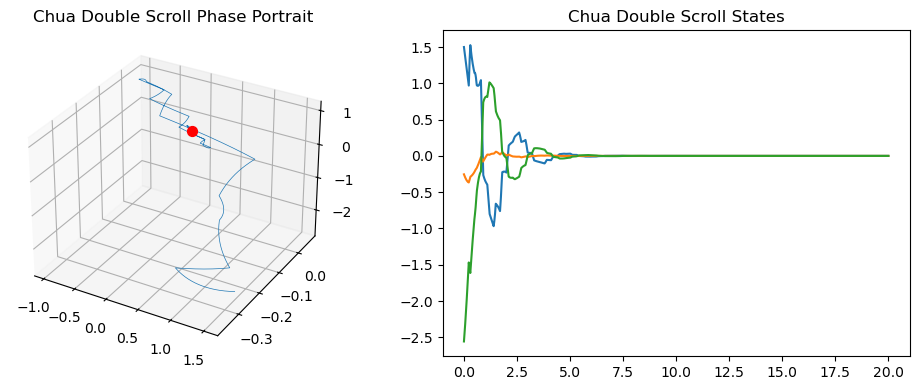

In [2]:
# Chua's Parameters
alpha, beta, m0, m1 = 9.3515, 14.79, -1.138, -0.722
chua_star = np.array([0.0, 0.0, 0.0])
chua_K = np.array([[46.8954, 123.5023, 14.6824], [4.7652, 12.5495, 1.4919], [-31.4526, -82.8327, -9.8475]])
chua_init = np.array([1.5, -0.2538, -2.5565])

def chua_ode(x):
    f_x1 = m1 * x[0] + 0.5 * (m0 - m1) * (abs(x[0] + 1) - abs(x[0] - 1))
    return np.array([alpha * (x[1] - x[0] - f_x1), 
                    x[0] - x[1] + x[2], 
                    -beta * x[1]])

t, h = run_simulation(chua_ode, chua_star, chua_K, tau=0.1, delta=1.8, initial_state=chua_init, t_max=20)
plot_results(t, h, chua_star, "Chua Double Scroll")

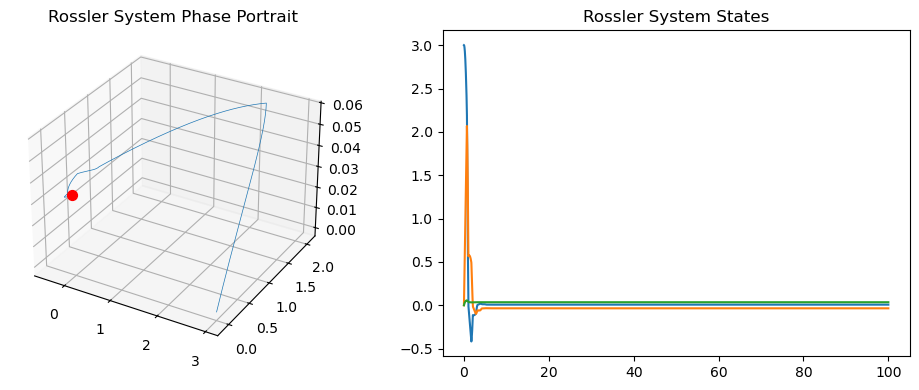

In [9]:
# Rossler Parameters
a_r, b_r, c_r = 0.2, 0.2, 5.7
ross_star = np.array([0.007, -0.0352, 0.0352])
ross_K = np.array([[4.3069, 6.2911, -0.5525], [-6.2911, 3.0078, 1.1599], [0.0194, 0.0408, -0.0021]])

ross_init = np.array([3.0, 0.0, 0.0]) 

def rossler_ode(x):
    return np.array([
        -x[1] - x[2],                 
        x[0] + a_r * x[1],             
        b_r + x[2] * (x[0] - c_r)      
    ])

t, h = run_simulation(rossler_ode, ross_star, ross_K, tau=0.35, delta=5, initial_state=ross_init, t_max=100)
plot_results(t, h, ross_star, "Rossler System")